# ADP 25회 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: 기출문제 모음 PDF pp.4~5

원 자료 조건: 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'25회';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')

# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 구매 고객 세분화

소매업체는 거래 내역으로 고객별 구매 빈도와 구매 금액을 요약해 마케팅 집단을 만들려 한다. 이 대문항의 집계·군집·해석은 같은 고객 자료를 이어 사용한다.

자료: retail.csv

### 1-1

고객별 구매빈도 F와 총 구매액 M을 정의·계산하고 분포를 탐색하시오. 거래 단위와 고객 단위를 구분하시오.

**판단 및 풀이 근거**

상품 행 수와 주문 빈도를 혼동하지 않도록 F는 고유 InvoiceNo입니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

               F            M
count  60.000000    60.000000
mean   12.500000  1889.959667
std     2.890663   741.818455
min     7.000000   601.280000
25%    11.000000  1326.675000
50%    13.000000  1906.470000
75%    14.000000  2301.102500
max    21.000000  4101.270000


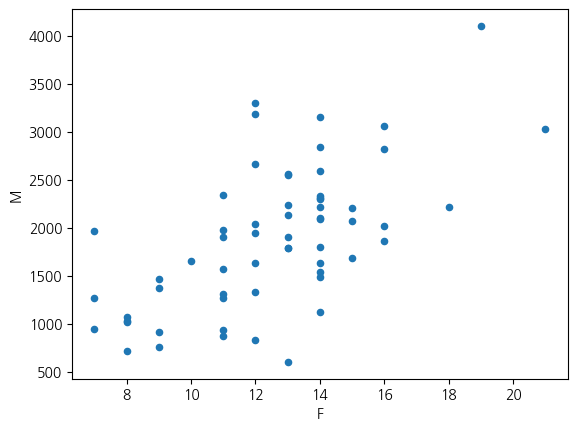

In [2]:
set_question('1-1')
retail=load('retail.csv');retail['amount']=retail.Quantity*retail.UnitPrice;fm=retail.groupby('CustomerID').agg(F=('InvoiceNo','nunique'),M=('amount','sum'));print(fm.describe());fm.plot.scatter('F','M');plt.show()

### 1-2

극단 고객과 단위 차이가 거리에 미치는 영향을 검토하시오. 처리·표준화 후 후보 집단 수를 비교하고 선택 근거를 제시하시오.

**판단 및 풀이 근거**

긴 꼬리에는 log1p 후 표준화를 적용합니다. silhouette/inertia는 상대 적합성 근거이며 자동 정답이 아닙니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

   k  silhouette    inertia
0  2    0.518791  49.494028
1  3    0.341739  37.305380
2  4    0.315378  28.662075
3  5    0.359047  23.272491


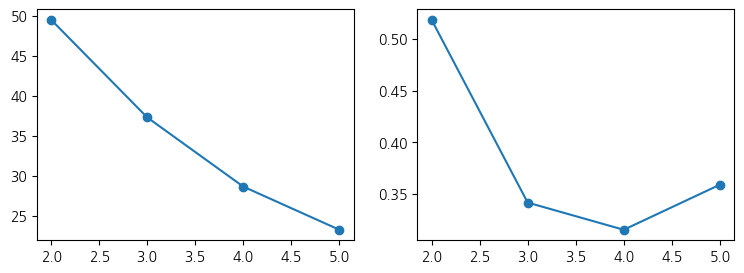

       CustomerID       F          M  clust
clust                                      
0         1230.20   9.550  1144.4320    0.0
1         1229.15  13.975  2262.7235    1.0


In [3]:
set_question('1-2')
fm_cluster,fm_choices=cluster(np.log1p(fm),OUT,original=fm.reset_index())

### 1-3

앞에서 정한 집단의 내부 응집과 집단 간 분리를 정량적으로 평가하시오. 하나의 평가 지표만으로 세분화가 유용하다고 단정할 수 없는 이유를 설명하시오.

**판단 및 풀이 근거**

군집 대표값·분포와 내부 점수의 방향을 함께 설명합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [4]:
set_question('1-3')
print(fm_choices);print('표준화된 log F/M silhouette가 클수록 내부 응집·분리가 상대적으로 좋음. 군집 수·초기화에 민감합니다.')

   k  silhouette    inertia
0  2    0.518791  49.494028
1  3    0.341739  37.305380
2  4    0.315378  28.662075
3  5    0.359047  23.272491
표준화된 log F/M silhouette가 클수록 내부 응집·분리가 상대적으로 좋음. 군집 수·초기화에 민감합니다.


### 1-4

집단별 고객 수·구매 빈도·금액을 요약하시오. 결과에 근거한 실행 가능한 마케팅 제안과 효과를 확인할 추가 검증을 제시하시오.

**판단 및 풀이 근거**

군집 번호 자체에 우수/불량 의미를 붙이지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [5]:
set_question('1-4')
print(fm_cluster.groupby('clust')[['F','M']].agg(['count','mean','median']));print('높은 F/M 고객: 유지·서비스, 낮은 F/높은 M 고객: 재구매 실험. 합성 그룹이므로 실제 효과는 A/B 검증 필요.')

          F                    M                    
      count    mean median count       mean   median
clust                                               
0        20   9.550    9.0    20  1144.4320  1048.87
1        40  13.975   14.0    40  2262.7235  2170.77
높은 F/M 고객: 유지·서비스, 낮은 F/높은 M 고객: 재구매 실험. 합성 그룹이므로 실제 효과는 A/B 검증 필요.


## 2. 수요의 계절 변화

별도 월별 시계열에서 계절 패턴을 반영해 향후 수요를 예측하려 한다. 보류 구간은 후보 선택과 전처리 적합에 쓰지 않는다.

자료: series.csv

### 2-1

날짜 간격·결측·추세·반복 패턴을 탐색하시오. 결측 처리 범위와 계절 구조 반영의 필요성을 설명하시오.

**판단 및 풀이 근거**

누락은 시간 격자를 유지하며 보간합니다. 미래 관측을 학습 보간에 사용하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

date     0
value    1
dtype: int64


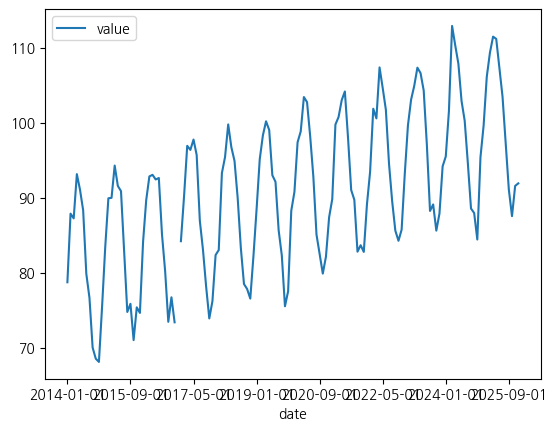

In [6]:
set_question('2-1')
demand=load('series.csv');print(demand.isna().sum());demand.plot(x='date',y='value');plt.show()

### 2-2

계절 구조를 반영한 후보를 학습 자료에서 비교·적합하고 고정 보류 구간을 예측하시오. RMSE·MAE와 계절 주기·선택 기준을 보고하시오.

**판단 및 풀이 근거**

학습 AIC 후보 선택과 보류 RMSE/MAE를 구분합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

       order         AIC  converged
0  (1, 0, 0)  622.840191       True
1  (1, 1, 0)  577.509094       True
2  (0, 1, 1)  550.375506       True
{'order': (0, 1, 1), 'RMSE': 2.946698388365361, 'MAE': 2.2161653630763243, 'ADF_train_p': 0.9896278942247749}


/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:997: UserWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  warn('Non-stationary starting seasonal autoregressive'
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No fre

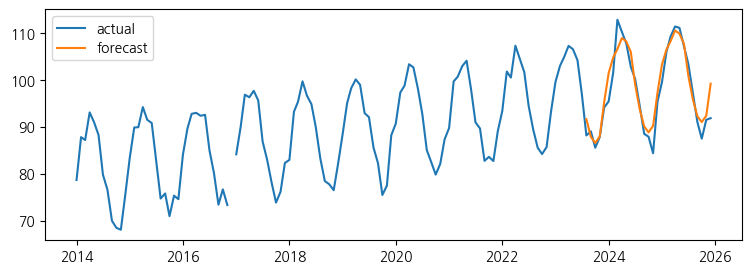

In [7]:
set_question('2-2')
demand_model,demand_metrics=seasonal_forecast(demand,OUT,12)

## 3. 경영 지표와 불확실성

속력·성장률·선호도·산포를 서로 다른 정의로 계산해야 하는 네 상황이다. 각 문항의 분모와 확률 모형을 구분한다.

자료: 데이터 없음

### 3-1

같은 거리를 갈 때 4km/h, 돌아올 때 5km/h로 이동했다. 왕복 평균 속력을 계산하고 단순 산술평균이 적절하지 않은 이유를 설명하시오.

**판단 및 풀이 근거**

거리 가중 시간이 같지 않으므로 산술평균 4.5가 아니라 조화평균을 사용합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [8]:
set_question('3-1')
speed=2/(1/4+1/5);print('harmonic mean speed:',speed)

harmonic mean speed: 4.444444444444445


### 3-2

연 매출이 3000→4000→5000으로 변했다. 두 해 동안의 연평균 복리 성장률을 계산하고 산술평균 성장률과 구분하시오.

**판단 및 풀이 근거**

두 기간의 성장계수 기하평균입니다. 세 관측값 자체의 기하평균을 성장률이라 부르지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [9]:
set_question('3-2')
growth=(5000/3000)**(1/2)-1;print('CAGR:',growth,'factor:',1+growth)

CAGR: 0.2909944487358056 factor: 1.2909944487358056


### 3-3

등산 선호 남성 20명·여성 15명, 수영 선호 남성 10명·여성 30명으로 이 두 활동이 전체 선호 범주다. 남성이라는 조건하 등산 선호 확률을 사건·분모와 함께 계산하시오.

**판단 및 풀이 근거**

분모는 전체가 아니라 남성 30명입니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [10]:
set_question('3-3')
print('P(hiking|male):',20/(20+10))

P(hiking|male): 0.6666666666666666


### 3-4

독립 정규 표본에서 n=10, 불편 표본분산이 90이다. 모집단 분산의 95% 신뢰구간을 구하고 사용 분포·자유도·정규성 가정과 구간 해석을 설명하시오.

**판단 및 풀이 근거**

chi-square 자유도 n-1, 큰 분위수는 하한 분모입니다. 정규성 가정이 필요합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [11]:
set_question('3-4')
variance_ci=(9*90/stats.chi2.ppf(.975,9),9*90/stats.chi2.ppf(.025,9));print(variance_ci)

(np.float64(42.58055444790953), np.float64(299.95672846672363))


## 4. 약 복용 전후 혈압

같은 20명의 혈압을 약 복용 전후에 측정했다. 개인 간에는 독립이고 개인별 차이(after-before)는 정규성을 만족한다고 작업 가정한다. 복용 후 감소했는지 유의수준 5%에서 평가한다.

자료: paired_bp.csv

### 4-1

자료의 짝 구조와 감소 방향을 반영한 검정을 선택하시오. 차이 변수·귀무가설·대립가설, 통계량·자유도·단측 p-value·기각 여부를 제시하고 약 복용 전후의 결론을 작성하시오.

**판단 및 풀이 근거**

같은 사람 전후의 차이에 대한 대응 t검정이다. d=after-before, H0: μd≥0, H1: μd<0. 독립 두 표본 검정을 사용하지 않으며 차이의 정규성을 확인한다.

**계산·해석 상세**

독립 두 표본 검정 대신 동일 대상의 paired 차이를 사용합니다. 양측 p/2는 t 부호 확인 없이 적용하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [12]:
set_question('4-1')
bp=load('paired_bp.csv');diff=bp.after-bp.before;t=diff.mean()/(diff.std(ddof=1)/np.sqrt(len(diff)));p=stats.t.cdf(t,len(diff)-1);print({'H0':'mean(after-before)>=0','H1':'mean(after-before)<0','t':t,'one_sided_p':p,'reject':p<.05});print('차이 정규성:',stats.shapiro(diff))

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_test('대응 t 감소 단측','mean(after-before) >= 0','mean(after-before) < 0',t,p,'복용 후 평균 혈압이 감소한다','개인 간 독립·전후 짝 유지·차이 정규성 작업 가정. 원인 효과에는 대조군 등 추가 설계 필요.',df=len(diff)-1)

{'H0': 'mean(after-before)>=0', 'H1': 'mean(after-before)<0', 't': np.float64(-3.1902840350750017), 'one_sided_p': np.float64(0.0024089830257660147), 'reject': np.True_}
차이 정규성: ShapiroResult(statistic=np.float64(0.9466946724427029), pvalue=np.float64(0.31968533906598195))
{
  "question": "4-1",
  "method": "대응 t 감소 단측",
  "H0": "mean(after-before) >= 0",
  "H1": "mean(after-before) < 0",
  "statistic": -3.1902840350750017,
  "p_value": 0.0024089830257660147,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "개인 간 독립·전후 짝 유지·차이 정규성 작업 가정. 원인 효과에는 대조군 등 추가 설계 필요.",
  "conclusion": "귀무가설을 기각한다. 복용 후 평균 혈압이 감소한다는 통계적 근거가 있다.",
  "df": 19
}


## 5. 공장별 생산량 분포

세 공장에서 독립적으로 뽑은 생산량 표본의 분포가 다른지 조사한다. 정규성은 가정하지 않는다. 유의수준 5%이며 중앙값만 비교하려면 분포 형태의 추가 가정이 필요하다.

자료: production.csv

### 5-1

세 독립 집단을 비교할 적절한 검정을 선택하고 이유를 설명하시오. 귀무·대립가설, 통계량·p-value·기각 여부와 생산량 분포의 결론을 제시하시오. 결과만으로 어느 쌍이 다른지 단정하지 마시오.

**판단 및 풀이 근거**

정규성을 가정하지 않는 세 독립 집단의 분포 비교이므로 Kruskal-Wallis 순위 검정을 선택한다. H0: 세 분포 동일, H1: 적어도 한 분포 다름. 중앙값 차이에는 같은 분포 형태 가정이 추가로 필요하다.

**계산·해석 상세**

독립 표본의 순위 분포 차이를 검사합니다. 중앙값 차이로만 해석하려면 분포 형태 유사성이 추가로 필요합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [13]:
set_question('5-1')
production=load('production.csv');groups=[g.output.to_numpy() for _,g in production.groupby('factory')];h,p=stats.kruskal(*groups);print({'H':h,'p_value':p,'reject':p<.05})

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_test('Kruskal-Wallis 독립 순위 비교','세 공장 생산량 분포가 같다','하나 이상의 공장 분포가 다르다',h,p,'공장별 생산량 분포가 다르다','독립 표본·동률 보정·순위 비교. 후속 쌍 차이는 별도 다중 비교가 필요.',df=len(groups)-1)

{'H': np.float64(13.40129032258065), 'p_value': np.float64(0.0012301180220801269), 'reject': np.True_}
{
  "question": "5-1",
  "method": "Kruskal-Wallis 독립 순위 비교",
  "H0": "세 공장 생산량 분포가 같다",
  "H1": "하나 이상의 공장 분포가 다르다",
  "statistic": 13.40129032258065,
  "p_value": 0.0012301180220801269,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "독립 표본·동률 보정·순위 비교. 후속 쌍 차이는 별도 다중 비교가 필요.",
  "conclusion": "귀무가설을 기각한다. 공장별 생산량 분포가 다르다는 통계적 근거가 있다.",
  "df": 2
}


## 6. 투자 대안 선택

다섯 투자안의 기간별 현금흐름이 제공된다. 표의 금액은 모두 순유입·초기 비용 0이라는 보완 조건과 할인율 .05에서 비교한다. 원자료에서 편익과 비용이 불명확한 한계를 구분한다.

자료: npv.csv

### 6-1

대안별 순현재가치를 계산하고 같은 할인·시점 규칙 아래 최대 대안을 선정하시오. 할인율·현금흐름 가정의 변화와 분석 목적의 한계를 설명하시오.

**판단 및 풀이 근거**

PDF의 예산을 실제 순편익으로 단정할 수 없습니다. 가정·초기투자·할인율 변경에 따라 판단이 바뀝니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [14]:
set_question('6-1')
cash=load('npv.csv');rate=.05;npv={c:float(np.sum(cash[c]/(1+rate)**cash.year)) for c in cash if c!='year'};print(npv,'max:',max(npv,key=npv.get));print('동일 금액이 비용이면 최소 현재비용을 선택해야 합니다.')

{'plan1': 40.621963070942655, 'plan2': 43.397041356225024, 'plan3': 47.321023647554256, 'plan4': 52.33344131303315, 'plan5': 63.18108195659215} max: plan5
동일 금액이 비용이면 최소 현재비용을 선택해야 합니다.
